# Using Google Colab

Read through the **Getting started** paragraph in the [official documentation](https://colab.research.google.com/). You may also want to take a look into the **More resources** section.

To add a new code block or text block, use the buttons in the menus above or hover your mouse between two blocks, where more buttons should appear.

To execute all code blocks within this document, select `Runtime -> Run all`. When you submit your solution, this should run without throwing an error.

Sometimes, previously defined variables cause trouble in later executions. If this is the case, you can select `Runtime -> Restart runtime` to restart the runtime and erase all previous definitions.

# Guidelines for Solving the Assignments

In these assignments, you are expected to implement the algorithms yourself rather than relying on Python’s built-in functions that already solve essential parts of the task, such as `index`, `min`, `max`, or `sort`. However, it is of course fine to use general-purpose functions like `len` or `range`.

You may discuss the assignments in general terms with other groups to clarify ideas, but every group must produce their own solutions independently. Copying solutions (or parts thereof) from other groups or from external sources is strictly prohibited—this includes material generated by AI text generators such as ChatGPT or similar tools.

# Work Distribution


Hannes: Runtime comparison

Huanyu: Better DNA hashing

Joel: Hash table implementation

Nora: DNA Hashing

*Note: Every group member individually implemented all questions, and then one person's answer was chosen per question for this document.*


# Initialisation

This section contains code that is later used to test, measure and plot your implementations. You need to run it once to initialise it.

⇩ Click here to initialise the code.

In [ ]:
# @title
import unittest

class TestHashTable(unittest.TestCase):
  def setUp(self):
    self.hash_table = HashTable(11, lambda e: e % 11)

  def test_insert(self):
    self.assertTrue(self.hash_table.insert(1, 4))
    self.assertFalse(self.hash_table.insert(1, 5))
    self.assertTrue(self.hash_table.insert(12, 6))
    self._test_buckets(1)

  def test_search(self):
    self.test_insert()
    self.assertEqual(self.hash_table.search(1), 4)
    self.assertIsNone(self.hash_table.search(2))
    self.assertEqual(self.hash_table.search(12), 6)

  def test_delete(self):
    self.test_insert()
    self.assertTrue(self.hash_table.delete(1))
    self.assertIsNone(self.hash_table.search(1))
    self.assertFalse(self.hash_table.delete(1))
    self.assertFalse(self.hash_table.delete(2))
    self.assertTrue(self.hash_table.delete(12))
    self.assertIsNone(self.hash_table.search(12))
    self.assertFalse(self.hash_table.delete(12))
    self._test_buckets()

  def _test_buckets(self, i=None):
    self.assertEqual(
        self.hash_table.buckets,
        [[(1, 4), (12, 6)] if idx == i else [] for idx in range(11)]
    )

import random
import time
import matplotlib.pyplot as plt

ht_sizes = [10**i for i in range(1, 4)]
entry_nums = [125 * (j + 1) for j in range(16)]

def plot_runtimes():
  rts = {ht_size: {entry_num: [] for entry_num in entry_nums } for ht_size in ht_sizes}

  for _ in range(5):
    for ht_size in ht_sizes:
      for entry_num in entry_nums:
        ht = HashTable(ht_size, lambda e: e % ht_size)
        start_time = time.time()
        for _ in range(entry_num):
          ht.insert(random.randrange(1_000_000), None)
        for _ in range(entry_num):
          ht.search(random.randrange(1_000_000))
        end_time = time.time()
        rts[ht_size][entry_num].append(end_time - start_time)

  for ht_size in ht_sizes:
    rt = [min(rts[ht_size][entry_num]) for entry_num in entry_nums]
    plt.plot(entry_nums, rt, label="hash table size: " + str(ht_size))

  plt.xlabel('Number of insert and search operations (N)')
  plt.ylabel('Runtime (seconds)')
  plt.title('Runtime vs Elements')

  plt.legend()
  plt.show()

# Hash Tables

### 1. Hash Table Implementation (4 points)

In this exercise, you will implement the class `HashTable`. We will use chaining for collision resolution. Internally, the data of the table is stored as a list of buckets, where each bucket is a list of key-value pairs. Note that compared to what was presented in the lecture, our implementation uses Python lists instead of linked lists for the buckets. Also, the lecture only focusses on the key of the table entries, but we will need to also store data for each entry. For this, we will use the Python *tuple* type: `(key, value)`.

**Example:**
```
def hash_fun(key):
  return key % 4

ht = HashTable(4, hash_fun)
ht.insert(1, "value_1")
ht.insert(5, "value_2")
ht.insert(3, "value_3")
print(ht.buckets)
```
This code creates a new hash table of size 4 that uses the hash function `h(k) = k mod 4`. It then inserts the three key-value pairs `(1, "value_1")`, `(5, "value_2")` and `(3, "value_3")`. The print statement will output:
```
[[], [(1, 'value_1'), (5, 'value_2')], [], [(3, 'value_3')]]
```

To pass all tests, you must implement these functions:
- `insert(key, value)`: If the key is present in the table, return `False`. Otherwise save the key-value-pair and return `True`.
- `search(key)`: If the key is present in the table, return the value associated with it. Otherwise return None.
- `delete(key)`: If the key is present in the table, remove the key-value-pair associated with it and return `True`. Otherwise return `False`.

Furthermore, the class has already the following functions implemented:
- `__init__(size, fun)`: Construct a new hash table of the given `size` that uses the hash function `fun` for all operations.
- `print()`: Print the contents of the hash table to the console. *(Used in exercise 3 and 4 - you can adapt this function to your needs if you wish.)*

All hash functions can be assumed to return integer values in the range `[0, size)`.

**Remark about Python classes**

If you do not know Object Oriented Programming and have never seen classes, or at least not in Python, all you need to know is the following. Inside the methods that you need to implement, you can access the hash function and the bucket list using `self.fun` and `self.buckets`, respectively.

In [ ]:
class HashTable:
  def __init__(self, size, fun):
    self.fun = fun
    self.buckets = [[] for _ in range(size)]

  def insert(self, key, value):
    # first we find which bucket our key belongs to
    idx = self.fun(key)
    bucket = self.buckets[idx]

    # we check if it is already in the bucket (we dont want duplicates)
    for k, v in bucket:
      if k == key:
        return False

    # otherwise we add the key and its value together
    bucket.append((key, value))
    return True

  def search(self, key):
    # same as insert, we first go to the corresponding bucket
    idx = self.fun(key)
    for k, v in self.buckets[idx]:
      if k == key:
        return v
    return None

  def delete(self, key):
    idx = self.fun(key)
    bucket = self.buckets[idx]

    # here we need the position as well so we can remove the pair
    for i in range(len(bucket)):
      if bucket[i][0] == key:
        del bucket[i]
        return True
    return False

  def print(self):
    for (idx, bucket) in enumerate(self.buckets):
      print("bucket {:2d}: {:5d} elements".format(idx, len(bucket)))

# run the tests
unittest.main(argv=[''], defaultTest='TestHashTable', verbosity=2, exit=False)

test_delete (__main__.TestHashTable.test_delete) ... ok
test_insert (__main__.TestHashTable.test_insert) ... ok
test_search (__main__.TestHashTable.test_search) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.007s

OK


### 2. Runtime Comparison (2 points)

The following code will test your hash table implementation. For three differently sized hash tables (size 10, 100 and 1000) and different values of N, it measures the runtime of the following sequence of operations:

- create an empty hash table
- insert N elements into the hash table
- search for N elements in the hash table

The code will create a plot, where N is on the x-axis and the runtime is on the y-axis.

Compare the reported runtimes. What do you observe? How do you explain your observations?

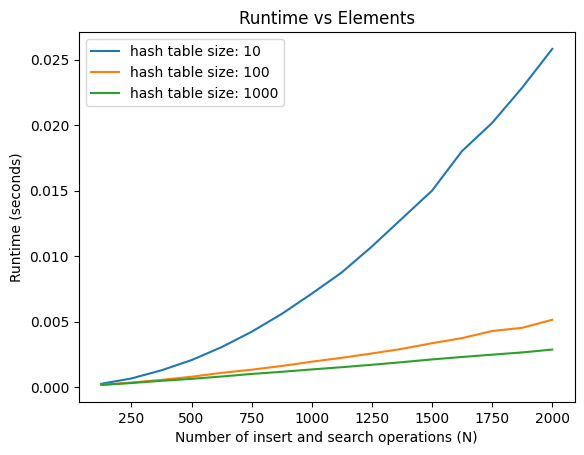

In [ ]:
plot_runtimes()

**Answer:**

From the output of the answer it looks like the bigger the size of the hash table the faster the run time. This is probably due to the loading factor. With a smaller hash table size there will be more collisions, resulting in a longer running time since the function has to look longer through the list. With less collisions given the bigger hash table size, it is faster. Every time you insert, the code has to look through all the available lists, which, if you have say 1000 elements, that is 100 elements / 10 (hash table size) meaning 10 elements per bucket. When the hash table size is 100 or 1000 as for this comparison, the code does not have to look through as much.

### 3. DNA Hashing (2 points)

In DNA, there are four types of bases, abbreviated as A (Adenine), T (Thymine), C (Cytosine), and G (Guanine). These bases are the building blocks of DNA, and they form the genetic code that carries instructions for the development, functioning, and characteristics of living organisms. They occur in pairs, specifically as AT, TA, CG, and GC. A segment of the double-stranded DNA consisting of e.g. five base pairs can be written as a string like `(AT)(CG)(AT)(CG)(GC)`.

> Note: Biologists usually write only one strand (e.g. ACACG), since the complementary strand is implied.

Below, we define the functions:
- `random_dna(n)` returns a random dna string that contains `n` base pairs.
- `dna_test(ht)` inserts 1000 random dna strings containing `10` base pairs into the hashtable `ht` and prints the resulting buckets.
- `h_dna(e)` is a hash function that returns the value $\sum_{i=1}^{\operatorname{len}(e)} |e_i| \mod 19$, where $|e_i|$ is the ASCII-value of the $i$-th letter of the string $e$. In words, the sum of the character values of all characters in the
string, modulo 19.

Run the test and inspect its output. How does the hash function perform? Explain the results.

In [ ]:
import random

def random_dna(n):
  return "".join(f"({random.choice(['AT','TA','CG','GC'])})" for _ in range(n))

def dna_test(ht):
  for _ in range(1000):
    ht.insert(random_dna(10), None)
  ht.print()

def h_dna(e):
  return sum(map(ord, e)) % 19

dna_test(HashTable(19, h_dna))

bucket  0:   123 elements
bucket  1:     2 elements
bucket  2:     0 elements
bucket  3:   254 elements
bucket  4:     0 elements
bucket  5:     0 elements
bucket  6:   113 elements
bucket  7:     0 elements
bucket  8:    52 elements
bucket  9:     8 elements
bucket 10:     0 elements
bucket 11:   207 elements
bucket 12:     0 elements
bucket 13:     0 elements
bucket 14:   182 elements
bucket 15:     0 elements
bucket 16:     8 elements
bucket 17:    51 elements
bucket 18:     0 elements


**Answer:**

ASCII values for the letter:\
A - 65\
C - 67\
G - 71\
T - 84\
( - 40\
) - 41\
Total values for each pair:\
(AT) - 230\
(TA) - 230\
(CG) - 219\
(GC) - 219
Since it strand is made up of exactly 10 pairs, and two of each pair have the same value, we can calculate every possible combination of values and then the value they would be assigned to from the hash function (h(k) = k%19) simply as:


    heuristic_values = list()
    for i in range(10):
      heuristic_values.append((230\*i+219\*(10-i))%19)
The results give the list below, which also represents the normal probability distribution of all pairs, where 11 and 3 represent the average, most likely case, whereas 5 and 9 have the lowest probability.\
[5, 16, 8, 0, 11, 3, 14, 6, 17, 9]\
Sorting this list, we can easily check that this is the case by comparing against the buckets of the hash table, and seeign how only the indeces of buckets in heuristic_values have elements.:\
[0, 3, 5, 6, 8, 9, 11, 14, 16, 17]
because the resutls of the heuristic can only reach these 10 possible hash values, we end up with holes in the hash table where no possible value can end up. THis is highly inefficient, as the allocated space is wasted.


### 4. Better DNA Hashing (2 points - hard question)

Improve the hashing function from the previous task, so that all buckets contain roughly an equal number of elements. Do not change the size of the hash table.

In [ ]:
def h_dna_2(e):
    k = 0
    # give each character a different weight based on its position
    for i in range(len(e)):
        k = k + (i + 1) * ord(e[i])
    # use the multiplication method to calculate the hash value
    return int(19 * ((k * 0.618) % 1))

dna_test(HashTable(19, h_dna_2))

bucket  0:    68 elements
bucket  1:    47 elements
bucket  2:    42 elements
bucket  3:    59 elements
bucket  4:    60 elements
bucket  5:    45 elements
bucket  6:    53 elements
bucket  7:    39 elements
bucket  8:    44 elements
bucket  9:    58 elements
bucket 10:    48 elements
bucket 11:    56 elements
bucket 12:    53 elements
bucket 13:    52 elements
bucket 14:    56 elements
bucket 15:    52 elements
bucket 16:    61 elements
bucket 17:    55 elements
bucket 18:    51 elements
